# 01 — Coleta Georreferenciada (GeoSampa + Street View) e Auditoria do Pré-Label Genérico (Etapa 0)

Este notebook documenta e reproduz a **Etapa 0** do pipeline **ArborGrid Vision**:
1. **Amostragem Territorial Multi-Zona**: Integração entre o cadastro oficial de árvores viárias da Prefeitura de São Paulo (**GeoSampa WFS** — `geoportal:arvore`) e o **Google Street View Static/Metadata API**, com captura em múltiplos ângulos (*visada frontal* + *visada lateral de paralaxe*).
2. **Pré-Rotulagem Zero-Shot (`YOLOE-11L-seg` + `MobileCLIP-BLT` + Heurística HSV/Canny)**: Como geramos máscaras preliminares para as primeiras **68 imagens (`pacote_1_prelabel`)** antes de existir qualquer modelo supervisionado treinado no domínio urbano de São Paulo.
3. **Auditoria Empírica (`Pré-Label Genérico` vs `Gabarito Humano do Pacote 1`)**: Medição direta de *Intersection over Union* (IoU) comprovando por que o pré-label genérico poupou quase todo o contorno manual das copas arbóreas, mas exigiu redesenho manual completo para a fiação elétrica.
4. **Empacotamento Reprodutível (`arborgrid_v3_gold_dataset.zip`)**: Verificação do pacote consolidado de treinamento para execução nos notebooks de nuvem (`colab/`).

In [1]:
import json
import sys
import zipfile
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

BASE_DIR = Path.cwd()
if str(BASE_DIR / "scripts") not in sys.path:
    sys.path.insert(0, str(BASE_DIR / "scripts"))

from vision_utils import (
    COLORS_BGR,
    add_legend_bar,
    json_to_masks,
    render_overlay,
    stamp_header,
)

plt.rcParams["figure.dpi"] = 120
plt.rcParams["font.sans-serif"] = ["Segoe UI", "DejaVu Sans", "Arial"]
print(f"Diretório base do projeto: {BASE_DIR}")

Diretório base do projeto: C:\Users\User\Documents\_FIAP\2026\Global Solution 2 - CitizenTech\arborgrid-vision


## 1. Inventário Territorial: GeoSampa WFS + Google Street View (`manifest.json`)

O arquivo declarativo `dataset/sp_geosampa_api/regions.json` define as zonas amostrais de São Paulo (incluindo o corredor de controle negativo da **Avenida Paulista**, onde a rede elétrica é 100% subterrânea). O inventário consolidado em `dataset/sp_geosampa_api/manifest.json` armazena as coordenadas SIRGAS 2000 / WGS84, distância câmera-árvore, azimutes (`heading`) e pares de visadas por indivíduo arbóreo.

In [2]:
manifest_path = BASE_DIR / "dataset" / "sp_geosampa_api" / "manifest.json"
regions_path = BASE_DIR / "dataset" / "sp_geosampa_api" / "regions.json"

manifest = json.loads(manifest_path.read_text(encoding="utf-8"))
regions_cfg = json.loads(regions_path.read_text(encoding="utf-8"))

rows_reg = []
for rid, rinfo in regions_cfg["regions"].items():
    trees_r = [t for t in manifest["trees"] if t.get("region_key") == rid]
    views_r = sum(len(t.get("views", [])) for t in trees_r)
    dual_view = sum(1 for t in trees_r if len(t.get("views", [])) >= 2)
    rows_reg.append({
        "Região (ID)": rid,
        "Descrição da Zona": rinfo["label"],
        "Tipo de Rede": "Subterrânea (Controle)" if rinfo["grid_type"] == "underground_control" else "Aérea Convencional",
        "Árvores Coletadas": len(trees_r),
        "Imagens Street View": views_r,
        "Pares Estéreo (2 Ângulos)": dual_view,
    })

df_regions = pd.DataFrame(rows_reg)
display(df_regions)
print(f"Total Consolidado: {len(manifest['trees'])} árvores | {sum(df_regions['Imagens Street View'])} imagens Street View (640x640).")

Total Consolidado: 271 árvores | 536 imagens Street View (640x640).


Região (ID),Descrição da Zona,Tipo de Rede,Árvores Coletadas,Imagens Street View,Pares Estéreo (2 Ângulos)
pinheiros,Pinheiros (Zona Oeste),Aérea Convencional,89,173,84
alto_da_mooca,Alto da Mooca (Zona Leste),Aérea Convencional,54,108,54
vila_mariana,Vila Mariana / Chácara Klabin (Centro-Sul),Aérea Convencional,54,108,54
avenida_paulista,Avenida Paulista (Corredor Subterrâneo — Controle Negativo),Subterrânea (Controle),74,147,73
campo_belo,Campo Belo (Zona Sul),Aérea Convencional,0,0,0
moema,Moema (Zona Sul),Aérea Convencional,0,0,0
perdizes,Perdizes / Pompeia (Zona Oeste),Aérea Convencional,0,0,0
saude,Saúde / Mirandópolis (Zona Sul),Aérea Convencional,0,0,0


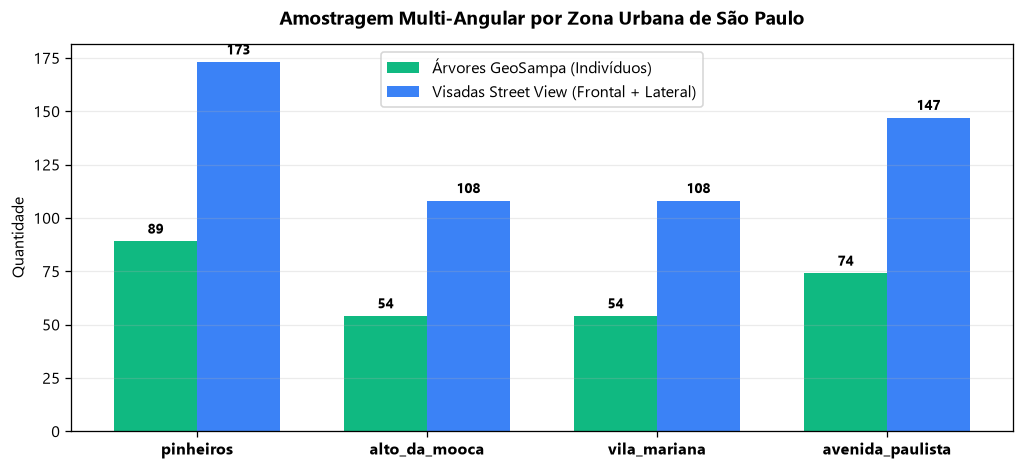

In [3]:
# Visualização da distribuição geográfica de coleta nas zonas ativas
df_active = df_regions[df_regions["Árvores Coletadas"] > 0].copy()

_, ax = plt.subplots(figsize=(9, 4.2))
x = np.arange(len(df_active))
w = 0.36
b1 = ax.bar(x - w/2, df_active["Árvores Coletadas"], width=w, label="Árvores GeoSampa (Indivíduos)", color="#10b981")
b2 = ax.bar(x + w/2, df_active["Imagens Street View"], width=w, label="Visadas Street View (Frontal + Lateral)", color="#3b82f6")

ax.set_xticks(x)
ax.set_xticklabels(df_active["Região (ID)"], fontweight="bold")
ax.set_ylabel("Quantidade")
ax.set_title("Amostragem Multi-Angular por Zona Urbana de São Paulo", fontweight="bold", pad=12)
ax.legend(frameon=True)
ax.grid(axis="y", alpha=0.25)

for bar in list(b1) + list(b2):
    h = int(bar.get_height())
    ax.annotate(f"{h}", (bar.get_x() + bar.get_width() / 2, h), xytext=(0, 3),
                textcoords="offset points", ha="center", va="bottom", fontsize=9, fontweight="bold")

plt.tight_layout()
plt.show()

## 2. Auditoria Empírica da Etapa 0: `pacote_1_prelabel` vs `pacote_1` (Gabarito Humano)

Para acelerar a criação do primeiro conjunto de treinamento sem partir do zero absoluto, aplicamos nas 68 imagens do **Pacote 1** uma pipeline híbrida zero-shot:
- **Copa Arbórea (`copa`)**: Segmentação zero-shot via `YOLOE-11L-seg` acoplado ao codificador textual `MobileCLIP-BLT` com interseção de máscara de vegetação em espaço de cor HSV.
- **Fiação Aérea (`fiacao`)**: Filtragem morfológica *Black-Hat / Top-Hat* combinada com detector de bordas Canny e Transformada de Hough Probabilística restrita à metade superior da imagem.

Abaixo, comparamos pixel a pixel os arquivos JSON originais de saída da pré-rotulagem (`dataset/workspace_xanylabeling/pacote_1_prelabel/`) contra os JSONs finais revisados manualmente no **X-AnyLabeling** (`dataset/workspace_xanylabeling/pacote_1/`):

In [4]:
ws_dir = BASE_DIR / "dataset" / "workspace_xanylabeling"
pre_dir = ws_dir / "pacote_1_prelabel"
gold_dir = ws_dir / "pacote_1"

audit_rows = []
for gold_json in sorted(gold_dir.glob("*.json")):
    stem = gold_json.stem
    pre_json = pre_dir / f"{stem}.json"
    if not pre_json.exists():
        continue

    pre_t, pre_w = json_to_masks(pre_json, 640, 640)
    gt_t, gt_w = json_to_masks(gold_json, 640, 640)

    inter_t = int(np.logical_and(pre_t > 0, gt_t > 0).sum())
    union_t = int(np.logical_or(pre_t > 0, gt_t > 0).sum())
    iou_t = (inter_t / union_t * 100.0) if union_t > 0 else 100.0

    inter_w = int(np.logical_and(pre_w > 0, gt_w > 0).sum())
    union_w = int(np.logical_or(pre_w > 0, gt_w > 0).sum())
    iou_w = (inter_w / union_w * 100.0) if union_w > 0 else 100.0

    audit_rows.append({
        "stem": stem,
        "pre_copa_px": int(pre_t.sum()),
        "gt_copa_px": int(gt_t.sum()),
        "iou_copa_pct": round(iou_t, 2),
        "pre_wire_px": int(pre_w.sum()),
        "gt_wire_px": int(gt_w.sum()),
        "iou_wire_pct": round(iou_w, 2),
    })

df_pre_audit = pd.DataFrame(audit_rows)
summary_etapa0 = pd.DataFrame([
    {
        "Classe Semântica": "Copa Arbórea (copa)",
        "IoU Médio Pré-Label vs Gabarito (%)": round(df_pre_audit["iou_copa_pct"].mean(), 2),
        "IoU Mediano (%)": round(df_pre_audit["iou_copa_pct"].median(), 2),
        "Imagens com IoU > 85%": int((df_pre_audit["iou_copa_pct"] > 85.0).sum()),
        "Diagnóstico de Esforço Humano": "Polígonos aproveitados quase integralmente (mínimo ajuste fino)",
    },
    {
        "Classe Semântica": "Fiação Aérea (fiacao)",
        "IoU Médio Pré-Label vs Gabarito (%)": round(df_pre_audit["iou_wire_pct"].mean(), 2),
        "IoU Mediano (%)": round(df_pre_audit["iou_wire_pct"].median(), 2),
        "Imagens com IoU > 85%": int((df_pre_audit["iou_wire_pct"] > 85.0).sum()),
        "Diagnóstico de Esforço Humano": "Forte ruído geométrico; exigiu substituição manual no X-AnyLabeling",
    },
])
display(summary_etapa0)

Classe Semântica,IoU Médio Pré-Label vs Gabarito (%),IoU Mediano (%),Imagens com IoU > 85%,Diagnóstico de Esforço Humano
Copa Arbórea (copa),96.39,100.00,65,Polígonos aproveitados quase integralmente (mínimo ajuste fino)
Fiação Aérea (fiacao),42.69,22.61,25,Forte ruído geométrico; exigiu substituição manual no X-AnyLabeling


### 2.1 Prova Visual Direta: Pré-Label Genérico vs. Gabarito Humano (`Pacote 1`)

A visualização abaixo renderiza duas amostras reais do **Pacote 1** lado a lado com o pré-label genérico e o gabarito humano final:

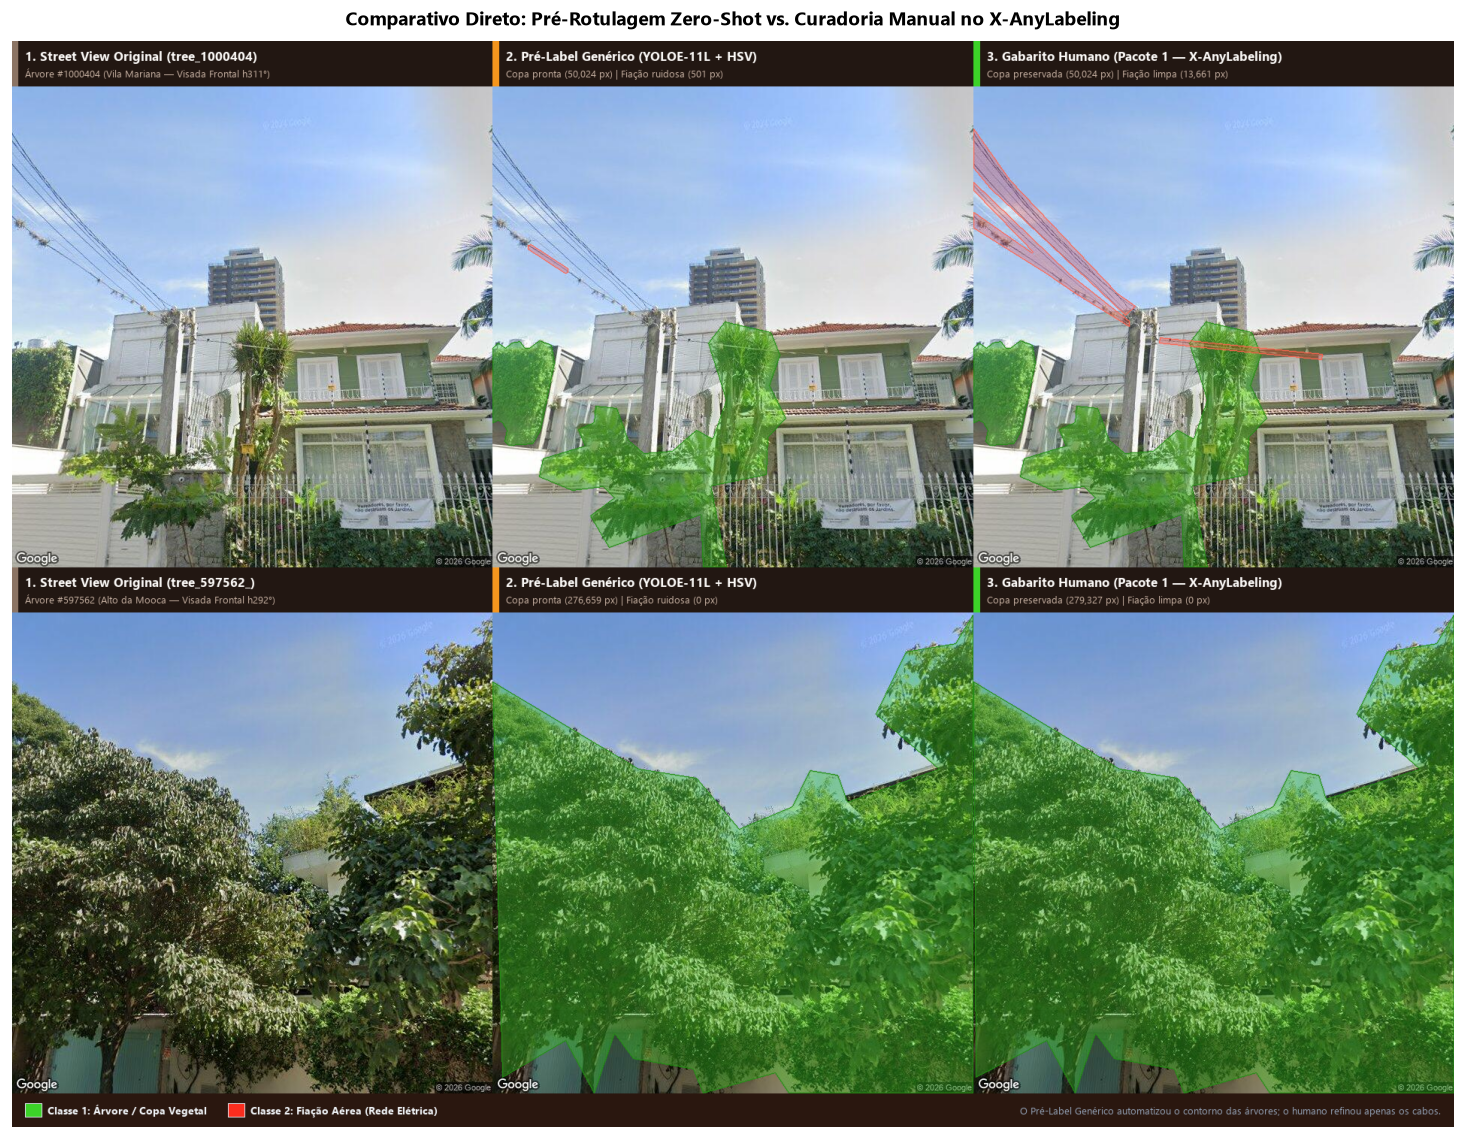

In [5]:
samples = [
    ("tree_1000404_center_front_h311", "Árvore #1000404 (Vila Mariana — Visada Frontal h311°)"),
    ("tree_597562_center_front_h292", "Árvore #597562 (Alto da Mooca — Visada Frontal h292°)"),
]
rows_vis = []
for stem, title in samples:
    img = cv2.imread(str(gold_dir / f"{stem}.jpg"))
    pre_t, pre_w = json_to_masks(pre_dir / f"{stem}.json", 640, 640)
    gt_t, gt_w = json_to_masks(gold_dir / f"{stem}.json", 640, 640)

    p1 = stamp_header(img, f"1. Street View Original ({stem[:12]})", title, (100, 116, 139))
    p2 = stamp_header(
        render_overlay(img, pre_t, pre_w),
        "2. Pré-Label Genérico (YOLOE-11L + HSV)",
        f"Copa pronta ({int(pre_t.sum()):,} px) | Fiação ruidosa ({int(pre_w.sum()):,} px)",
        (30, 150, 245),
    )
    p3 = stamp_header(
        render_overlay(img, gt_t, gt_w),
        "3. Gabarito Humano (Pacote 1 — X-AnyLabeling)",
        f"Copa preservada ({int(gt_t.sum()):,} px) | Fiação limpa ({int(gt_w.sum()):,} px)",
        (40, 210, 60),
    )
    rows_vis.append(np.hstack([p1, p2, p3]))

mosaic_etapa0 = add_legend_bar(
    np.vstack(rows_vis),
    [
        (COLORS_BGR["arvore"], "Classe 1: Árvore / Copa Vegetal"),
        (COLORS_BGR["fiacao"], "Classe 2: Fiação Aérea (Rede Elétrica)"),
    ],
    footer_note="O Pré-Label Genérico automatizou o contorno das árvores; o humano refinou apenas os cabos.",
)

plt.figure(figsize=(15, 10))
plt.imshow(cv2.cvtColor(mosaic_etapa0, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.title("Comparativo Direto: Pré-Rotulagem Zero-Shot vs. Curadoria Manual no X-AnyLabeling", fontweight="bold", pad=10)
plt.tight_layout()
plt.show()

## 3. Verificação do Dataset Consolidado para Treinamento em Nuvem (`arborgrid_v3_gold_dataset.zip`)

Para garantir reprodutibilidade total entre o ambiente local e os notebooks de treinamento pesado em GPU no Google Colab (`colab/Colab_01_Ablation_V1_e_Treino_V2_1024px.ipynb` e `colab/Colab_02_Treino_Final_V3_ABC_1024px.ipynb`), todos os pacotes curados no X-AnyLabeling são empacotados em `dataset/arborgrid_v3_gold_dataset.zip`:

In [6]:
zip_path = BASE_DIR / "dataset" / "arborgrid_v3_gold_dataset.zip"
pkg_summary = []
for pkg_name, role_desc in [
    ("pacote_1_prelabel", "Saída bruta do Pré-Label Genérico (Auditoria Etapa 0)"),
    ("pacote_1", "Pacote 1 Revisado (54 Treino + 14 Validação Hold-out)"),
    ("pacote_2", "Pacote 2 Expandido (Pré-rotulado com V1 1024px e refinado)"),
    ("pacote_3_hard_negatives", "Pacote 3 Hard Negatives (Av. Paulista — 100% Subterrânea)"),
]:
    pdir = ws_dir / pkg_name
    n_jpg = len(list(pdir.glob("*.jpg")))
    n_json = len(list(pdir.glob("*.json")))
    pkg_summary.append({
        "Pacote": pkg_name,
        "Imagens (.jpg)": n_jpg,
        "Anotações (.json)": n_json,
        "Papel no Ciclo Human-in-the-Loop": role_desc,
    })

display(pd.DataFrame(pkg_summary))
if zip_path.exists():
    with zipfile.ZipFile(zip_path, "r") as zf:
        print(f"Arquivo ZIP verificado: {zip_path.name} ({zip_path.stat().st_size / (1024*1024):.2f} MB | {len(zf.namelist())} entradas).")

Pacote,Imagens (.jpg),Anotações (.json),Papel no Ciclo Human-in-the-Loop
pacote_1_prelabel,71,71,Saída bruta do Pré-Label Genérico (Auditoria Etapa 0)
pacote_1,68,68,Pacote 1 Revisado (54 Treino + 14 Validação Hold-out)
pacote_2,57,57,Pacote 2 Expandido (Pré-rotulado com V1 1024px e refinado)
pacote_3_hard_negatives,18,18,Pacote 3 Hard Negatives (Av. Paulista — 100% Subterrânea)
